# E-Commerce Customer Segmentation using RFM

**Author:** Utkarsh Singh

**Aim:** Group the customers of an online retailer into segments using **K-Means** and **DBSCAN** on RFM data, reduce dimensions with **PCA**, visualise the segments with **t-SNE**, and describe each segment as a marketing persona.

**RFM**
* **Recency**: how many days ago the customer last bought something
* **Frequency**: how many orders the customer placed
* **Monetary**: how much money the customer spent in total

**Dataset:** [Online Retail, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail) (Daqing Chen, released under CC BY 4.0). It has all transactions of a UK-based online gift retailer between 01-12-2010 and 09-12-2011.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

## 1. Load the data

In [2]:
df = pd.read_csv("data/online_retail.csv", encoding="ISO-8859-1")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Missing values in each column
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

## 2. Clean the data
* Remove rows with no `CustomerID` (we cannot assign them to a customer).
* Remove rows with negative or zero `Quantity` (these are cancelled or returned orders) and zero `UnitPrice`.
* Create `TotalPrice = Quantity x UnitPrice` for every row.

In [4]:
df = df.dropna(subset=["CustomerID"])
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print("Rows after cleaning:", df.shape[0])
print("Number of customers:", df["CustomerID"].nunique())

Rows after cleaning: 397884
Number of customers: 4338


## 3. Create the RFM table
For Recency we need a reference date. We take **one day after the last invoice date** in the data.

In [5]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,   # Recency
    "InvoiceNo": "nunique",                                    # Frequency
    "TotalPrice": "sum"                                        # Monetary
})
rfm.columns = ["Recency", "Frequency", "Monetary"]

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [6]:
rfm.describe().round(1)

,Recency,Frequency,Monetary
count,4338.0,4338.0,4338.0
mean,92.5,4.3,2054.3
std,100.0,7.7,8989.2
min,1.0,1.0,3.8
25%,18.0,1.0,307.4
50%,51.0,2.0,674.5
75%,142.0,5.0,1661.7
max,374.0,209.0,280206.0


## 4. Prepare the data for clustering
Look at the histograms: Frequency and Monetary are **highly skewed** (a few customers buy a lot, most buy little). K-Means and DBSCAN use distances, so these large values would dominate. We therefore:
1. take the **log** of the values to reduce the skew, and
2. **scale** them (mean 0, standard deviation 1) so that R, F and M count equally.

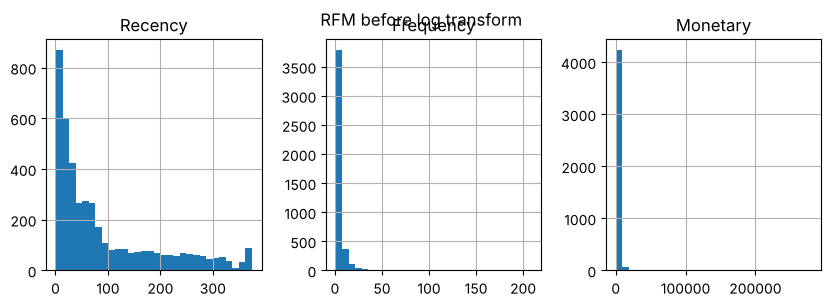

In [7]:
rfm.hist(bins=30, figsize=(10, 3), layout=(1, 3))
plt.suptitle("RFM before log transform")
plt.show()

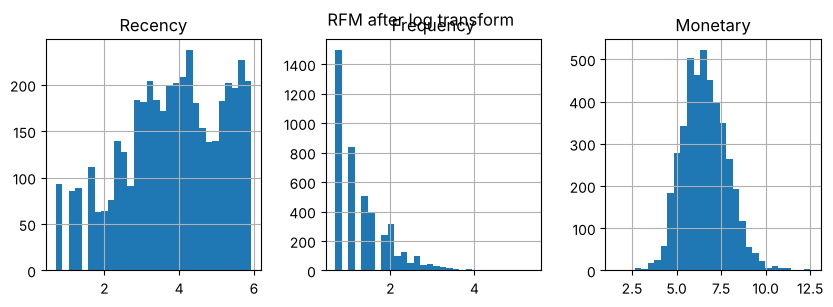

In [8]:
rfm_log = np.log1p(rfm)

rfm_log.hist(bins=30, figsize=(10, 3), layout=(1, 3))
plt.suptitle("RFM after log transform")
plt.show()

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

## 5. PCA (dimensionality reduction)
PCA converts the 3 features (R, F, M) into new uncorrelated features called principal components. We keep the first **2 components** so that the customers can be drawn on a 2-D plot.

In [9]:
pca = PCA(n_components=2)
pca_data = pca.fit_transform(rfm_scaled)

print("Variance explained by PC1 and PC2:", pca.explained_variance_ratio_.round(3))
print("Total variance kept:", round(pca.explained_variance_ratio_.sum(), 3))

Variance explained by PC1 and PC2: [0.751 0.188]
Total variance kept: 0.939


The first two components keep most of the information, so the 2-D picture is a good summary of the 3-D data.

## 6. K-Means clustering

### Choosing the number of clusters (Elbow method)
We run K-Means for k = 1 to 10 and plot the **inertia** (sum of squared distances of points to their cluster centre). We look for the point where the curve starts to flatten (the elbow).

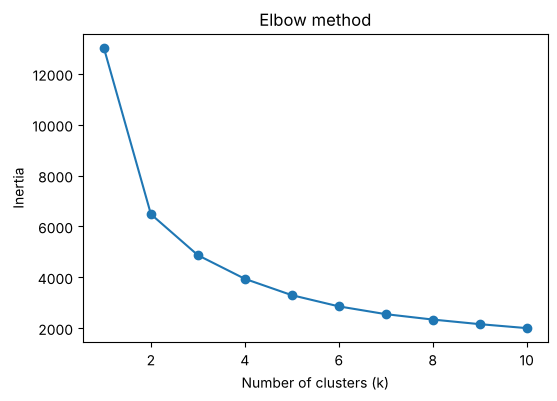

In [10]:
inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(rfm_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.savefig("images/elbow.png", bbox_inches="tight")
plt.show()

In [11]:
# Silhouette score (higher is better, maximum 1)
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(rfm_scaled)
    print("k =", k, " silhouette =", round(silhouette_score(rfm_scaled, labels), 3))

k = 2  silhouette = 0.433
k = 3  silhouette = 0.337


k = 4  silhouette = 0.337
k = 5  silhouette = 0.316


k = 6  silhouette = 0.313


The elbow is not very sharp: the curve flattens gradually after k = 3 or 4. The silhouette score is best for k = 2 (only "active" and "inactive" customers), which is too general for marketing. k = 3 and k = 4 have the same score, so we choose **k = 4** because it gives four different groups that are easy to describe.

In [12]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
rfm["KMeans"] = kmeans.fit_predict(rfm_scaled)

rfm["KMeans"].value_counts().sort_index()

KMeans
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64

## 7. DBSCAN clustering
DBSCAN groups points that are close together (dense regions) and marks isolated points as **noise** (label -1). It has two parameters:
* `eps`: the radius of the neighbourhood
* `min_samples`: minimum points needed in a neighbourhood to form a dense region

We try three values of `eps` and see how the result changes.

In [13]:
for eps in [0.3, 0.5, 0.7]:
    db = DBSCAN(eps=eps, min_samples=10)
    labels = db.fit_predict(rfm_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    print("eps =", eps, "| clusters =", n_clusters, "| noise points =", n_noise)

eps = 0.3 | clusters = 7 | noise points = 442
eps = 0.5 | clusters = 2 | noise points = 79
eps = 0.7 | clusters = 1 | noise points = 39


In [14]:
dbscan = DBSCAN(eps=0.5, min_samples=10)
rfm["DBSCAN"] = dbscan.fit_predict(rfm_scaled)

rfm["DBSCAN"].value_counts()

DBSCAN
 0    2780
 1    1479
-1      79
Name: count, dtype: int64

With `eps = 0.5` DBSCAN finds **2 large clusters** and a small number of **noise points** (very unusual customers). With a small `eps` it splits the data into many small groups, and with a large `eps` everything merges into one group. RFM data is one continuous cloud of points without clear gaps, so DBSCAN cannot split it into detailed segments. K-Means gives more useful groups for marketing, while DBSCAN is helpful for finding outliers.

## 8. Visualisation with PCA and t-SNE
**PCA plot:** a straight (linear) projection onto the first two components.
**t-SNE plot:** a non-linear method that keeps customers who are similar close together. It is used only for visualisation.

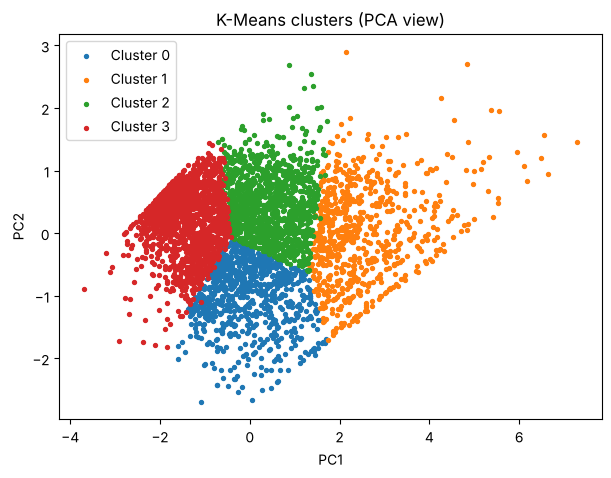

In [15]:
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

plt.figure(figsize=(7, 5))
for c in range(4):
    plt.scatter(pca_data[rfm["KMeans"] == c, 0], pca_data[rfm["KMeans"] == c, 1],
                s=8, color=colors[c], label="Cluster " + str(c))
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means clusters (PCA view)")
plt.legend()
plt.savefig("images/pca_clusters.png", bbox_inches="tight")
plt.show()

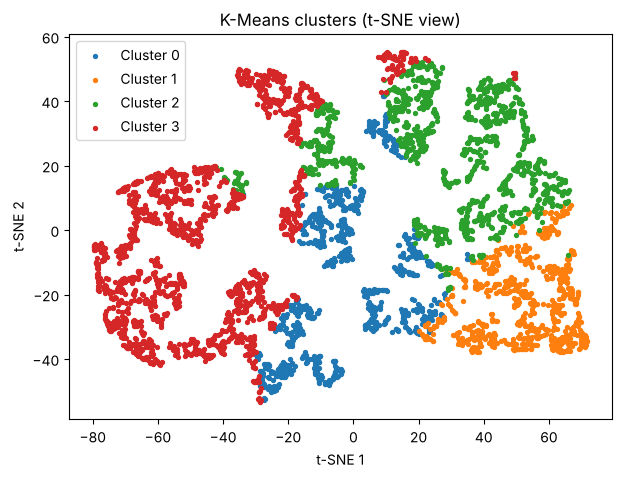

In [16]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_data = tsne.fit_transform(rfm_scaled)

plt.figure(figsize=(7, 5))
for c in range(4):
    plt.scatter(tsne_data[rfm["KMeans"] == c, 0], tsne_data[rfm["KMeans"] == c, 1],
                s=8, color=colors[c], label="Cluster " + str(c))
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("K-Means clusters (t-SNE view)")
plt.legend()
plt.savefig("images/tsne_clusters.png", bbox_inches="tight")
plt.show()

Both plots show that the four K-Means clusters occupy different regions, so the segments are meaningful.

## 9. Understanding each segment
We calculate the average Recency, Frequency and Monetary value of each cluster, plus the share of customers and the share of revenue.

In [17]:
profile = rfm.groupby("KMeans").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
)
profile["Customers_%"] = profile["Customers"] / profile["Customers"].sum() * 100
profile["Revenue_%"] = profile["Total_Revenue"] / profile["Total_Revenue"].sum() * 100

profile.round(1)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customers_%,Revenue_%
KMeans,,,,,,,
0,837,18.1,2.1,551.8,461873.0,19.3,5.2
1,716,12.1,13.7,8074.3,5781175.1,16.5,64.9
2,1173,71.1,4.1,1802.8,2114718.4,27.0,23.7
3,1612,182.5,1.3,343.5,553641.5,37.2,6.2


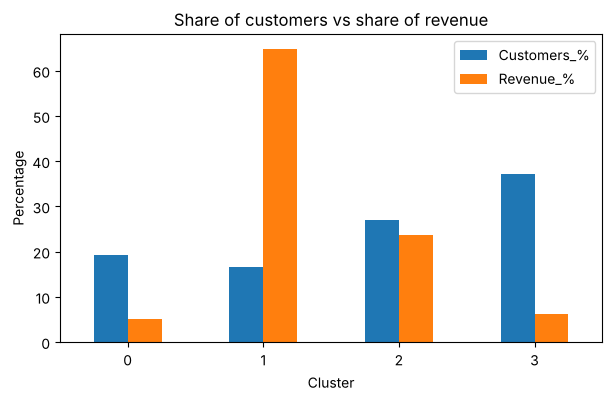

In [18]:
profile[["Customers_%", "Revenue_%"]].plot(kind="bar", figsize=(7, 4))
plt.xlabel("Cluster")
plt.ylabel("Percentage")
plt.title("Share of customers vs share of revenue")
plt.xticks(rotation=0)
plt.savefig("images/customers_vs_revenue.png", bbox_inches="tight")
plt.show()

## 10. Marketing personas
Based on the table above (low Recency = bought recently):

| Cluster | Persona | Behaviour | Marketing action |
|---|---|---|---|
| 1 | **Champions** | Bought very recently, order very often and spend the most. Only about 16% of customers but about 65% of revenue. | Reward them: loyalty programme, early access to new products, no heavy discounts. |
| 2 | **Regular customers** | Moderate number of orders and spend, but have not bought for a couple of months. | Remind them with personalised offers and recommendations before they become inactive. |
| 0 | **New customers** | Bought recently but only 1-2 orders and low spend. | Welcome email, small discount on the second purchase to build the habit. |
| 3 | **Lost customers** | Last purchase was about 6 months ago, usually a single order, low spend. About 37% of customers but only about 6% of revenue. | Cheap win-back email or clearance offer; do not spend much marketing budget here. |

In [19]:
persona_names = {1: "Champions", 2: "Regular customers", 0: "New customers", 3: "Lost customers"}
rfm["Persona"] = rfm["KMeans"].map(persona_names)

rfm["Persona"].value_counts()

Persona
Lost customers       1612
Regular customers    1173
New customers         837
Champions             716
Name: count, dtype: int64

## 11. Conclusion
* RFM features, scaled after a log transform, are suitable for clustering customers.
* PCA keeps most of the variance in 2 components and helps to visualise the customers.
* K-Means with k = 4 gives four meaningful customer segments. A small group of **Champions** brings roughly two-thirds of the revenue, so keeping them satisfied is the most important task.
* DBSCAN finds two broad groups and a few outliers because RFM data has no clear gaps between segments.
* t-SNE confirms that the K-Means segments are located in different regions.

**Limitations:** only purchase history is used (no product type, age or location), and the personas should be tested with real marketing campaigns.